# Earnings-at-Risk for Colombian Banks: Loan and Deposit Betas through the 2021–2026 Rate Cycle, Machine-Learning Drivers of Pass-Through, and Monte Carlo Net-Interest-Margin Distributions Backtested against the Hikes and Cuts

Earnings-at-risk (EaR) asks how much a bank's net interest income could fall over the next year if interest rates move against it. The answer depends on two sets of numbers that are hard to observe: how fast and how fully each bank passes rate changes through to its loans and to its deposits (its *betas*), and how far rates can plausibly move. Colombia offers an unusually informative test. Banco de la República cut its policy rate to 1.75% in 2020–2021, raised it to 13.25% by 2023, cut it to 9.25% by 2025 and raised it again to 12.25% in 2026. Each bank's loan yields and funding costs over these swings are published monthly, so betas can be measured bank by bank, their drivers modelled, and EaR forecasts checked against what actually happened.

**What it does.**

1. It downloads monthly balances and interest income and expense for every Colombian bank (2016–2026) and the deposit-rate reports with each bank's savings and CDT rates (2018–2026).
2. It measures, for each bank, the share of the policy-rate move passed through to its loan yield, deposit cost, savings rate and new-CDT rate in the 2021–2023 hiking cycle and the 2023–2025 cutting cycle, and how the net interest margin moved.
3. It models the monthly change in each bank's deposit cost from past policy-rate changes and bank characteristics (deposit mix, size, loan mix, capital) with a pooled distributed-lag model, the same model with characteristic interactions, and LightGBM, trained up to 2023 and tested on 2024–2026, and explains the LightGBM forecasts with tree SHAP values.
4. It simulates 5,000 twelve-month paths of the policy rate from a mean-reverting model with momentum, propagates them to each bank's loan yield and deposit cost through its shrunk betas, and reads off the distribution of its net interest margin: the expected margin, the 5th percentile and the earnings-at-risk.
5. It backtests the same procedure as of December 2021 (before the hikes) and December 2023 (before the cuts): were the banks' realised margins inside their forecast ranges?

**Data.** Superintendencia Financiera de Colombia via datos.gov.co: *Información financiera con fines de supervisión – CUIF por moneda* (mxk5-ce6w) and *Tasas de interés de captación y operaciones del mercado monetario* (axk9-g2nh).

**Methods.** Cycle betas, distributed-lag pass-through models with bank characteristics, LightGBM with out-of-time validation and tree SHAP explanations, empirical-Bayes shrinkage, a mean-reverting rate model with momentum and bootstrapped residuals, Monte Carlo net-interest-margin simulation, and forecast-interval backtests.

**Key output.** Each bank's loan and deposit betas in both directions; out-of-sample accuracy of the pass-through models and what drives them; each bank's twelve-month margin distribution and earnings-at-risk today; and the coverage of the forecast ranges in two historical backtests.

## 1. Betas, margins and earnings-at-risk

**Beta.** For a rate cycle from month *t*<sub>0</sub> to *t*<sub>1</sub>, a bank's loan beta is the change in its loan yield divided by the change in the policy rate; its deposit beta is the same ratio for its deposit cost. A bank whose deposit beta is below its loan beta gains margin when rates rise and loses it when they fall. Betas measured over a full cycle mix speed and size of pass-through; the distributed-lag models below separate them month by month.

**Margin.** The net interest margin (NIM) is net interest income over total assets, annualised. With balances held constant, a rate path *r*<sub>*t*</sub> changes it through loan yields and deposit costs:

ΔNIM<sub>*t*</sub> = (*L*/*A*) Δ*y*<sub>*L,t*</sub> − (*D*/*A*) Δ*c*<sub>*D,t*</sub>,  with  Δ*y*<sub>*t*</sub> = β Σ<sub>*k*</sub> *w*<sub>*k*</sub> Δ*r*<sub>*t−k*</sub>,

where *L*, *D* and *A* are loans, deposits and assets, β the bank's long-run beta and *w*<sub>*k*</sub> the share of pass-through that happens *k* months after the rate change.

**Earnings-at-risk.** Over many simulated rate paths, the bank's average NIM over the next twelve months has a distribution; EaR is its expected value minus its 5th percentile. Unlike a single parallel shock, it weights scenarios by how plausible they are and lets each bank's own betas and lags decide how much of the rate move reaches its income within the year.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import lightgbm as lgb

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2022
rng = np.random.default_rng(SEED)
SOCRATA = "https://www.datos.gov.co/resource/{}.json"
CUIF_ID, CAPT_ID = "mxk5-ce6w", "axk9-g2nh"
ACCOUNTS = {
    "100000": "assets",
    "140400": "mortgage",
    "140800": "consumer",
    "141000": "commercial",
    "141200": "microcredit",
    "210500": "current_acc",
    "210700": "cdt",
    "210800": "savings",
    "210900": "savings_special",
    "300000": "equity",
    "410200": "inc_loans",
    "410300": "inc_money_market",
    "410700": "inc_inv_fv",
    "411000": "inc_uvr",
    "411100": "inc_inv_ac",
    "510200": "exp_deposits",
    "510300": "exp_bank_loans",
    "510400": "exp_money_market",
    "510600": "exp_inv_fv",
}
FLOWS = [v for k, v in ACCOUNTS.items() if k[0] in "45"]
# CDT issuance buckets: 30 days to over 360 days
CDT_SUB = ["10", "40", "50", "70", "110", "130", "140"]
# savings accounts of persons, companies and public entities
SAV_SUB = ["10", "20", "30"]
CYCLES = {
    "hikes 2021–2023": ("2021-08-01", "2023-08-01"),
    "cuts 2023–2025": ("2023-11-01", "2025-09-01"),
}
# months of pass-through lags
LAGS = 12
TRAIN_END = "2023-12-31"
N_PATHS, HORIZON = 5_000, 12
MIN_ASSETS_COP_TN = 1.0

print(f"lightgbm {lgb.__version__} · run on {dt.date.today():%Y-%m-%d}")

lightgbm 4.7.0 · run on 2026-11-04


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

Income and expense accounts accumulate from January, so monthly flows are differences within each year. The source publishes a few months twice with identical values; duplicates are removed before the flows are computed. Yields and costs are monthly flows × 12 over average balances and smoothed over three months, because single months carry one-off items. Deposit-rate reports give each bank's amount-weighted savings and new-CDT rates; effective annual rates are converted to nominal (monthly compounding). The policy-rate proxy is the rate on repurchase operations with Banco de la República.

In [3]:
def socrata(dataset, params, page=50_000):
    out, off = [], 0
    while True:
        q = {**params, "$limit": page, "$offset": off}
        for k in range(5):
            try:
                r = requests.get(
                    SOCRATA.format(dataset), params=q, timeout=600
                )
                r.raise_for_status()
                rows = r.json()
                break
            except Exception:
                time.sleep(10 * (k + 1))
        else:
            raise RuntimeError(f"datos.gov.co query failed for {dataset}")
        out += rows
        if len(rows) < page:
            return pd.DataFrame(out)
        off += page


def fetch_cuif():
    acc = ",".join(f"'{a}'" for a in ACCOUNTS)
    return socrata(
        CUIF_ID,
        {
            "$select": (
                "fecha_corte, codigo_entidad, nombre_entidad, cuenta, valor"
            ),
            "$where": f"tipo_entidad='1' AND moneda='0' AND cuenta in({acc})",
            "$order": "fecha_corte, codigo_entidad, cuenta",
        },
    )


def fetch_capt():
    return socrata(
        CAPT_ID,
        {
            "$select": (
                "date_trunc_ym(fechacorte) as mes, codigoentidad, uca,"
                " subcuenta, sum(tasa*monto) as tm, sum(monto) as mt"
            ),
            "$where": "uca in('1','5','7') AND tipoentidad='1'",
            "$group": "mes, codigoentidad, uca, subcuenta",
            "$order": "mes, codigoentidad, uca, subcuenta",
        },
    )


CUIF = cached("cuif_banks", fetch_cuif, max_age_hours=24 * 7)
CAPT = cached("captacion_banks", fetch_capt, max_age_hours=24 * 7)
CUIF["valor"] = pd.to_numeric(CUIF["valor"])
n_raw = len(CUIF)
CUIF = CUIF.drop_duplicates(["codigo_entidad", "fecha_corte", "cuenta"])
CUIF["date"] = (
    pd.to_datetime(CUIF["fecha_corte"]).dt.to_period("M").dt.to_timestamp()
)
NAMES = (
    CUIF.sort_values("date")
    .groupby("codigo_entidad")["nombre_entidad"]
    .last()
    .str.replace(r"\s*S\.A\.?$", "", regex=True)
    .str.title()
)
P = CUIF.pivot_table(
    index=["codigo_entidad", "date"],
    columns="cuenta",
    values="valor",
    aggfunc="sum",
).rename(columns=ACCOUNTS)
P = P.reindex(columns=list(ACCOUNTS.values())).fillna(0.0).sort_index()
jan = P.index.get_level_values("date").month == 1
for c in FLOWS:
    P[c] = np.where(jan, P[c], P[c] - P[c].groupby(level=0).shift(1).fillna(0))
P["loans"] = P[["mortgage", "consumer", "commercial", "microcredit"]].sum(
    axis=1
)
P["deposits"] = P[["current_acc", "cdt", "savings", "savings_special"]].sum(
    axis=1
)
P["nii"] = P[
    ["inc_loans", "inc_money_market", "inc_inv_fv", "inc_uvr", "inc_inv_ac"]
].sum(axis=1) - P[
    ["exp_deposits", "exp_bank_loans", "exp_money_market", "exp_inv_fv"]
].sum(
    axis=1
)
latest = P.xs(P.index.get_level_values("date").max(), level="date")
BANKS = latest.index[latest["assets"] >= MIN_ASSETS_COP_TN * 1e12].tolist()
P = P.loc[P.index.get_level_values(0).isin(BANKS)]

g = P.groupby(level=0)
avg = lambda c: (P[c] + g[c].shift(1)) / 2
smooth = lambda s: s.groupby(level=0).transform(
    lambda x: x.rolling(3, min_periods=3).mean()
)
B = pd.DataFrame(index=P.index)
B["loan_yield"] = smooth(12 * P["inc_loans"] / avg("loans") * 100)
B["deposit_cost"] = smooth(12 * P["exp_deposits"] / avg("deposits") * 100)
B["nim"] = smooth(12 * P["nii"] / avg("assets") * 100)
B["loans_to_assets"] = P["loans"] / P["assets"]
B["deposits_to_assets"] = P["deposits"] / P["assets"]
B["savings_share"] = (P["savings"] + P["savings_special"]) / P["deposits"]
B["current_share"] = P["current_acc"] / P["deposits"]
B["cdt_share"] = P["cdt"] / P["deposits"]
B["consumer_share"] = P["consumer"] / P["loans"]
B["microcredit_share"] = P["microcredit"] / P["loans"]
B["equity_ratio"] = P["equity"] / P["assets"]
B["log_assets"] = np.log(P["assets"])

ea2nom = lambda ea: 12 * ((1 + ea / 100) ** (1 / 12) - 1) * 100
CAPT["mes"] = pd.to_datetime(CAPT["mes"])
for c in ["tm", "mt"]:
    CAPT[c] = pd.to_numeric(CAPT[c])
CAPT = CAPT[CAPT["mt"] > 0]
wavg = lambda d: ea2nom(
    d.groupby(["codigoentidad", "mes"])["tm"].sum()
    / d.groupby(["codigoentidad", "mes"])["mt"].sum()
)
SAVR = wavg(
    CAPT[(CAPT["uca"] == "7") & CAPT["subcuenta"].isin(SAV_SUB)]
).rename("savings_rate")
CDTR = wavg(
    CAPT[(CAPT["uca"] == "1") & CAPT["subcuenta"].isin(CDT_SUB)]
).rename("cdt_rate")
repo = (
    CAPT[(CAPT["uca"] == "5") & (CAPT["subcuenta"] == "230")]
    .groupby("mes")[["tm", "mt"]]
    .sum()
)
R = ea2nom(repo["tm"] / repo["mt"]).rename("policy")
RATES = pd.concat([SAVR, CDTR], axis=1)
RATES.index.names = ["codigo_entidad", "date"]
B = B.join(RATES, how="left")
print(
    f"{n_raw - len(CUIF):,} duplicated rows dropped · {len(BANKS)} banks ·"
    f" accounts {P.index.get_level_values('date').min():%Y-%m} to"
    f" {P.index.get_level_values('date').max():%Y-%m} · policy proxy"
    f" {R.index.min():%Y-%m} to {R.index.max():%Y-%m}, now {R.iloc[-1]:.2f}%"
    " nominal"
)

6,017 duplicated rows dropped · 30 banks · accounts 2016-01 to 2026-08 · policy proxy 2018-01 to 2026-10, now 11.64% nominal


## 4. Betas in both directions, bank by bank

For each cycle, betas are the change between the 3-month averages at the start and end dates divided by the change in the policy proxy over the same dates. The hiking cycle runs from August 2021 to August 2023 and the cutting cycle from November 2023 to September 2025; both end dates leave time for lagged pass-through.

In [4]:
def cycle_betas(t0, t1):
    t0, t1 = pd.Timestamp(t0), pd.Timestamp(t1)
    dr = R.loc[t1] - R.loc[t0]
    out = {}
    for b in BANKS:
        d = B.xs(b, level=0)
        if t0 not in d.index or t1 not in d.index:
            continue
        out[b] = {
            k: (d.loc[t1, c] - d.loc[t0, c]) / dr
            for k, c in [
                ("loan", "loan_yield"),
                ("deposit", "deposit_cost"),
                ("savings rate", "savings_rate"),
                ("new CDT rate", "cdt_rate"),
            ]
        }
        out[b]["NIM change (pp)"] = d.loc[t1, "nim"] - d.loc[t0, "nim"]
    return pd.DataFrame(out).T, dr


CB = {}
for name, (t0, t1) in CYCLES.items():
    CB[name], drc = cycle_betas(t0, t1)
    print(f"{name}: policy proxy moved {drc:+.2f} points")
CBT = pd.concat(CB, axis=1)
size = latest["assets"].reindex(CBT.index) / 1e12
wavg_b = lambda df: df.apply(
    lambda c: np.average(
        c.fillna(c.median()), weights=size.reindex(df.index).fillna(0)
    )
)
SUMB = pd.concat(
    {
        name: pd.DataFrame({
            "median bank": CB[name].median(),
            "asset-weighted": wavg_b(CB[name]),
        })
        for name in CB
    },
    axis=1,
)
display(
    SUMB.style.format("{:.2f}").set_caption(
        "Betas and margin changes by cycle"
    )
)
TOPB = CBT.loc[size.sort_values(ascending=False).index[:12]].copy()
TOPB.index = [NAMES[b] for b in TOPB.index]
hk, ct = CB["hikes 2021–2023"].align(
    CB["cuts 2023–2025"], join="inner", axis=0
)
ASYM = pd.Series({
    "banks whose deposit beta was lower in the cuts than in the hikes": (
        (ct["deposit"] < hk["deposit"]).mean()
    ),
    "banks whose NIM rose in the hikes": (
        (CB["hikes 2021–2023"]["NIM change (pp)"] > 0).mean()
    ),
    "banks whose NIM rose in the cuts": (
        (CB["cuts 2023–2025"]["NIM change (pp)"] > 0).mean()
    ),
    "correlation of hike and cut deposit betas": (
        hk["deposit"].corr(ct["deposit"])
    ),
    "banks in both cycles": len(hk),
})
display(ASYM.to_frame("share / value").style.format("{:.2f}"))
TOPB.style.format("{:.2f}").set_caption("The twelve largest banks")

hikes 2021–2023: policy proxy moved +10.78 points
cuts 2023–2025: policy proxy moved -3.64 points


,share / value
banks whose deposit beta was lower in the cuts than in the hikes,0.19
banks whose NIM rose in the hikes,0.26
banks whose NIM rose in the cuts,0.72
correlation of hike and cut deposit betas,0.90
banks in both cycles,27.00


## 5. What drives deposit pass-through? Out-of-time models

The target is the monthly change in each bank's (smoothed) deposit cost. Features are the policy-rate changes of the current and previous eleven months and the bank's characteristics in the previous month. Three models are trained on 2018–2023 and tested on every bank-month from January 2024 (cuts, then the 2026 hikes):

- **Pooled distributed lag (DL):** Δ*c*<sub>*b,t*</sub> = α + Σ<sub>*k*</sub> β<sub>*k*</sub> Δ*r*<sub>*t−k*</sub>.
- **DL with characteristics:** adds interactions of the cumulative 6- and 12-month policy change with the deposit-mix, size, loan-mix and capital variables, so each bank's beta depends on its balance sheet.
- **LightGBM** on the same raw features, with no interactions specified.

Tree SHAP values decompose each LightGBM forecast into feature contributions.

In [5]:
CHARS = [
    "savings_share",
    "current_share",
    "cdt_share",
    "consumer_share",
    "microcredit_share",
    "equity_ratio",
    "log_assets",
    "deposits_to_assets",
]
dR = R.diff()
LAGF = pd.DataFrame({f"dr_lag{k}": dR.shift(k) for k in range(LAGS)})
LAGF["dr_cum6"], LAGF["dr_cum12"] = R.diff(6), R.diff(12)
M = B.reset_index().rename(columns={"codigo_entidad": "bank"})
M = M.sort_values(["bank", "date"])
for c in CHARS:
    M[c] = M.groupby("bank")[c].shift(1)
M["target"] = M.groupby("bank")["deposit_cost"].diff()
M = M.merge(LAGF, left_on="date", right_index=True).dropna(
    subset=["target", "dr_cum12"] + CHARS
)
# drop accounting jumps (reclassifications)
M = M[M["target"].abs() < 2]
MU, SD = (
    M.loc[M["date"] <= TRAIN_END, CHARS].mean(),
    M.loc[M["date"] <= TRAIN_END, CHARS].std(),
)
for c in CHARS:
    z = (M[c] - MU[c]) / SD[c]
    M[f"{c}_x6"], M[f"{c}_x12"] = z * M["dr_cum6"], z * M["dr_cum12"]
LAG_COLS = [f"dr_lag{k}" for k in range(LAGS)]
INT_COLS = [f"{c}_x{h}" for c in CHARS for h in (6, 12)]
TR, TE = M[M["date"] <= TRAIN_END], M[M["date"] > TRAIN_END]


def ols(cols):
    X = np.c_[np.ones(len(TR)), TR[cols]]
    beta, *_ = np.linalg.lstsq(X, TR["target"], rcond=None)
    return beta, lambda d: np.c_[np.ones(len(d)), d[cols]] @ beta


b_dl, f_dl = ols(LAG_COLS)
b_dlx, f_dlx = ols(LAG_COLS + INT_COLS)
GF = LAG_COLS + ["dr_cum6", "dr_cum12"] + CHARS
GBM = lgb.train(
    dict(
        objective="huber",
        alpha=0.1,
        learning_rate=0.03,
        num_leaves=15,
        min_child_samples=40,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=1,
        verbose=-1,
        seed=SEED,
    ),
    lgb.Dataset(TR[GF], TR["target"]),
    500,
)
PRED = pd.DataFrame(
    {
        "pooled DL": f_dl(TE),
        "DL with characteristics": f_dlx(TE),
        "LightGBM": GBM.predict(TE[GF]),
        "no change": 0.0,
    },
    index=TE.index,
)


def cum_err(col):
    d = (
        TE[["bank", "date", "target"]]
        .assign(p=PRED[col])
        .sort_values(["bank", "date"])
    )
    e = d.groupby("bank")["p"].cumsum() - d.groupby("bank")["target"].cumsum()
    return e.abs().mean()


EVAL = pd.DataFrame({
    m: {
        "monthly RMSE (bp)": (
            np.sqrt(((PRED[m] - TE["target"]) ** 2).mean()) * 100
        ),
        "monthly MAE (bp)": (PRED[m] - TE["target"]).abs().mean() * 100,
        "cumulative error since 2024, mean abs. (bp)": cum_err(m) * 100,
        "correlation with actual": (
            np.corrcoef(PRED[m], TE["target"])[0, 1]
            if m != "no change"
            else np.nan
        ),
    }
    for m in PRED
}).T
LR_BETA = pd.Series({
    "pooled long-run deposit beta (12 months)": b_dl[1:].sum(),
    "share passed through within 3 months": b_dl[1:4].sum() / b_dl[1:].sum(),
    "share passed through within 6 months": b_dl[1:7].sum() / b_dl[1:].sum(),
    "train bank-months": len(TR),
    "test bank-months": len(TE),
})
SH = GBM.predict(TE[GF], pred_contrib=True)[:, :-1]
SHAP = pd.Series(np.abs(SH).mean(0), index=GF)
SHAP_G = pd.Series(
    {
        "policy-rate changes (lags and cumulative)": (
            SHAP[LAG_COLS + ["dr_cum6", "dr_cum12"]].sum()
        )
    }
    | {c: SHAP[c] for c in CHARS}
)
SHAP_G = (SHAP_G / SHAP_G.sum()).sort_values(ascending=False)
XDL = pd.Series(b_dlx[1 + LAGS :], index=INT_COLS)
display(LR_BETA.to_frame("value").style.format("{:.3f}"))
display(
    EVAL.style.format("{:.2f}").set_caption(
        "Out of time, January 2024 to today"
    )
)
display(SHAP_G.to_frame("share of mean |SHAP|").style.format("{:.1%}"))
XDL.sort_values().to_frame(
    "interaction coefficient (per s.d., per point of policy change)"
).style.format("{:+.4f}")

,value
pooled long-run deposit beta (12 months),0.778
share passed through within 3 months,0.562
share passed through within 6 months,0.927
train bank-months,1574.000
test bank-months,950.000


,monthly RMSE (bp),monthly MAE (bp),"cumulative error since 2024, mean abs. (bp)",correlation with actual
pooled DL,17.87,11.76,87.51,0.60
DL with characteristics,17.87,12.20,84.53,0.61
LightGBM,18.96,12.93,128.47,0.51
no change,22.79,17.46,231.76,nan


,share of mean |SHAP|
policy-rate changes (lags and cumulative),79.5%
cdt_share,4.4%
savings_share,4.3%
log_assets,2.9%
consumer_share,2.1%
current_share,2.0%
equity_ratio,1.8%
microcredit_share,1.6%
deposits_to_assets,1.4%


,"interaction coefficient (per s.d., per point of policy change)"
microcredit_share_x6,-0.0614
consumer_share_x6,-0.0443
savings_share_x6,-0.0368
log_assets_x12,-0.0160
current_share_x6,-0.0157
equity_ratio_x12,-0.0131
cdt_share_x12,-0.0121
deposits_to_assets_x12,-0.0077
current_share_x12,+0.0047
deposits_to_assets_x6,+0.0116


## 6. Earnings-at-risk today

**Rate model.** The monthly change of the policy proxy follows Δ*r*<sub>*t*</sub> = *c* + ρ Δ*r*<sub>*t*−1</sub> − κ *r*<sub>*t*−1</sub> + ε<sub>*t*</sub>: momentum (central banks move in steps in the same direction) and mean reversion. It is fitted on all months since 2018, and residuals are bootstrapped to simulate 5,000 twelve-month paths, with the rate floored at 0.5%.

**Bank betas.** Each bank's long-run loan and deposit betas are estimated from twelve-month changes since 2018 and shrunk towards the cross-bank average by empirical Bayes, so that banks with noisy histories borrow strength from the rest. The timing of pass-through follows the pooled distributed-lag profile, estimated separately for loans and deposits.

**Margin.** With balances fixed at today's levels, each path changes the NIM through loans and deposits only; investments, money-market positions and other items keep today's contribution. This gives the *rate-only* distribution.

**Everything else.** Margins also move with loan mix, fees booked as interest, investment income and one-off items. For every past month whose outcome is known, the bank's realised 12-month NIM change is compared with the change its betas imply for the rates that actually followed; these residuals (centred) are bootstrapped and added to the rate-only paths. EaR is the expected average NIM over the next year minus the 5th percentile of this total distribution; the rate-only EaR is reported alongside.

In [6]:
def lag_profile(col, end):
    Z = (
        B[[col]]
        .reset_index()
        .rename(columns={"codigo_entidad": "bank"})
        .sort_values(["bank", "date"])
    )
    Z["dy"] = Z.groupby("bank")[col].diff()
    Z = Z.merge(LAGF[LAG_COLS], left_on="date", right_index=True).dropna()
    Z = Z[(Z["date"] <= end) & (Z["dy"].abs() < 2)]
    beta, *_ = np.linalg.lstsq(
        np.c_[np.ones(len(Z)), Z[LAG_COLS]], Z["dy"], rcond=None
    )
    w = np.clip(beta[1:], 0, None)
    return w / w.sum() if w.sum() > 0 else np.full(LAGS, 1 / LAGS)


def shrunk_betas(col, end):
    est = {}
    for b in BANKS:
        y = B[col].xs(b, level=0).loc[:end]
        d = pd.concat([y.diff(12), R.diff(12)], axis=1, join="inner").dropna()
        # quarterly, to limit overlap
        d = d.iloc[::3]
        if len(d) < 8 or d.iloc[:, 1].std() < 0.5:
            continue
        x, yy = d.iloc[:, 1].to_numpy(), d.iloc[:, 0].to_numpy()
        bb = np.polyfit(x, yy, 1)[0]
        resid = yy - np.polyval(np.polyfit(x, yy, 1), x)
        se2 = resid.var(ddof=2) / ((x - x.mean()) ** 2).sum()
        est[b] = (bb, se2)
    E = pd.DataFrame(est, index=["beta", "se2"]).T
    mu = np.average(E["beta"], weights=1 / E["se2"])
    tau2 = max(E["beta"].var() - E["se2"].mean(), 1e-4)
    E["shrunk"] = (E["beta"] / E["se2"] + mu / tau2) / (
        1 / E["se2"] + 1 / tau2
    )
    return E["shrunk"], mu


def rate_paths(end, n=N_PATHS, h=HORIZON, seed=SEED):
    r = R.loc[:end]
    d = pd.DataFrame(
        {"dr": r.diff(), "dr1": r.diff().shift(1), "r1": r.shift(1)}
    ).dropna()
    X = np.c_[np.ones(len(d)), d["dr1"], d["r1"]]
    coef, *_ = np.linalg.lstsq(X, d["dr"], rcond=None)
    eps = d["dr"].to_numpy() - X @ coef
    g = np.random.default_rng(seed)
    paths = np.empty((n, h))
    rp, drp = np.full(n, r.iloc[-1]), np.full(n, r.iloc[-1] - r.iloc[-2])
    for t in range(h):
        dr_ = coef[0] + coef[1] * drp + coef[2] * rp + g.choice(eps, n)
        rp_new = np.maximum(rp + dr_, 0.5)
        drp, rp = rp_new - rp, rp_new
        paths[:, t] = rp
    return paths, coef, r


def propagate(full, LA, DA, betaL, betaD, wL, wD):
    """
    full: (n, LAGS + HORIZON) policy-rate changes, oldest first; returns the
    12-month average NIM change (pp) per row.
    """
    n = full.shape[0]
    dyL, dcD = np.zeros((n, HORIZON)), np.zeros((n, HORIZON))
    for t in range(HORIZON):
        # changes at lags 0..11 for month t + 1
        win = full[:, t + 1 : t + 1 + LAGS][:, ::-1]
        dyL[:, t], dcD[:, t] = betaL * (win @ wL), betaD * (win @ wD)
    return (LA * np.cumsum(dyL, 1) - DA * np.cumsum(dcD, 1)).mean(1)


def residuals(b, end, betaL, betaD, wL, wD):
    """
    Realised 12-month NIM change minus the rate-implied change, at every past
    origin whose outcome is known by `end`.
    """
    d = B.xs(b, level=0)
    dr = R.diff()
    out = []
    for tau in d.loc[
        : pd.Timestamp(end) - pd.DateOffset(months=HORIZON)
    ].index:
        seg = dr.loc[
            tau
            - pd.DateOffset(months=LAGS - 1) : tau
            + pd.DateOffset(months=HORIZON)
        ]
        fut = d["nim"].loc[
            tau + pd.DateOffset(months=1) : tau + pd.DateOffset(months=HORIZON)
        ]
        if (
            len(seg) != LAGS + HORIZON
            or seg.isna().any()
            or len(fut) < HORIZON
            or fut.isna().any()
            or pd.isna(d.loc[tau, "nim"])
        ):
            continue
        imp = propagate(
            seg.to_numpy()[None, :],
            d.loc[tau, "loans_to_assets"],
            d.loc[tau, "deposits_to_assets"],
            betaL,
            betaD,
            wL,
            wD,
        )[0]
        out.append(fut.mean() - d.loc[tau, "nim"] - imp)
    return np.array(out)


def ear(end, banks=None, realised_path=None):
    paths, coef, r = rate_paths(end)
    if realised_path is not None:
        paths = np.tile(realised_path, (N_PATHS, 1))
    # already-realised changes still passing through
    hist = r.diff().iloc[-LAGS:].to_numpy()
    full = np.c_[
        np.tile(hist, (N_PATHS, 1)),
        np.diff(np.c_[np.full(N_PATHS, r.iloc[-1]), paths], axis=1),
    ]
    wL, wD = lag_profile("loan_yield", end), lag_profile("deposit_cost", end)
    bL, muL = shrunk_betas("loan_yield", end)
    bD, muD = shrunk_betas("deposit_cost", end)
    g = np.random.default_rng(SEED + 1)
    out = {}
    for b in banks or BANKS:
        d = (
            B.xs(b, level=0)
            .loc[:end]
            .dropna(subset=["nim", "loan_yield", "deposit_cost"])
        )
        if len(d) < 24:
            continue
        base = d.iloc[-1]
        betaL, betaD = bL.get(b, muL), bD.get(b, muD)
        rate_part = base["nim"] + propagate(
            full,
            base["loans_to_assets"],
            base["deposits_to_assets"],
            betaL,
            betaD,
            wL,
            wD,
        )
        res = residuals(b, end, betaL, betaD, wL, wD)
        total = rate_part + (
            g.choice(res, N_PATHS) - res.mean() if len(res) >= 12 else 0.0
        )
        out[b] = {
            "bank": NAMES[b],
            "assets (COP tn)": (
                P.xs(b, level=0)["assets"].loc[:end].iloc[-1] / 1e12
            ),
            "loan beta": betaL,
            "deposit beta": betaD,
            "base NIM": base["nim"],
            "expected NIM, next 12m": rate_part.mean(),
            "rate-only 5th pct": np.percentile(rate_part, 5),
            "rate-only 95th pct": np.percentile(rate_part, 95),
            "rate-only EaR (bp)": (
                (rate_part.mean() - np.percentile(rate_part, 5)) * 100
            ),
            "5th percentile": np.percentile(total, 5),
            "95th percentile": np.percentile(total, 95),
            "EaR (bp of assets)": (
                (total.mean() - np.percentile(total, 5)) * 100
            ),
            "corr(NIM, rate)": (
                np.corrcoef(rate_part, paths.mean(1))[0, 1]
                if realised_path is None
                else np.nan
            ),
            "residual months": len(res),
        }
    RQ = pd.Series(
        np.percentile(paths[:, -1], [5, 50, 95]),
        index=["5th", "median", "95th"],
    )
    return pd.DataFrame(out).T, coef, RQ, wL, wD


EAR, COEF, RQ, WL, WD = ear(B.index.get_level_values("date").max())
EAR = EAR.sort_values("assets (COP tn)", ascending=False)
num = EAR.columns.drop("bank")
EAR[num] = EAR[num].astype(float)
RATE_MODEL = pd.Series({
    "momentum ρ": COEF[1],
    "mean reversion κ": -COEF[2],
    "implied long-run rate (%)": -COEF[0] / COEF[2],
    "policy proxy in 12 months, 5th pct (%)": RQ["5th"],
    "median (%)": RQ["median"],
    "95th pct (%)": RQ["95th"],
    "loan pass-through within 6 months": WL[:6].sum(),
    "deposit pass-through within 6 months": WD[:6].sum(),
})
display(RATE_MODEL.to_frame("value").style.format("{:.2f}"))
EAR.head(15).style.format({c: "{:.2f}" for c in num}).format(
    {"EaR (bp of assets)": "{:.0f}"}
).set_caption("Twelve-month NIM distribution, largest banks (%)")

,value
momentum ρ,0.46
mean reversion κ,0.00
implied long-run rate (%),15.39
"policy proxy in 12 months, 5th pct (%)",8.94
median (%),11.56
95th pct (%),15.13
loan pass-through within 6 months,0.87
deposit pass-through within 6 months,0.83


,bank,assets (COP tn),loan beta,deposit beta,base NIM,"expected NIM, next 12m",rate-only 5th pct,rate-only 95th pct,rate-only EaR (bp),5th percentile,95th percentile,EaR (bp of assets),"corr(NIM, rate)",residual months
7,Bancolombia,295.872053,0.653949,0.573821,6.368841,6.437067,6.397480,6.488583,3.958675,5.554677,7.288521,88,0.904947,80.000000
39,Banco Davivienda,159.974577,0.518013,0.715494,5.150821,5.068276,4.874424,5.221740,19.385198,4.507504,5.688578,56,-0.995459,80.000000
1,Banco De Bogota,144.362880,0.673260,0.697172,3.744438,3.713410,3.594672,3.808145,11.873779,2.500078,4.899148,121,-0.998883,80.000000
13,Bbva Colombia,121.388633,0.426378,0.620714,4.543110,4.412677,4.152871,4.616265,25.980573,3.906891,5.078400,51,-0.992550,80.000000
23,Banco De Occidente,84.476420,0.618249,0.788420,4.741764,4.646737,4.434079,4.815158,21.265763,3.699633,5.522794,95,-0.994761,80.000000
43,Banco Agrario De Colombia,44.010515,0.773450,0.178023,7.956234,8.267270,7.903694,8.727439,36.357630,6.853669,9.352371,141,0.983428,80.000000
42,Scotiabank Colpatria,39.150933,0.613613,0.765856,6.111645,6.031320,5.838341,6.184223,19.297807,5.197005,6.682493,83,-0.995752,80.000000
12,Banco Gnb Sudameris,35.129917,0.627709,0.969638,-0.084976,-0.476169,-1.168774,0.068347,69.260471,-1.389588,0.472594,91,-0.989603,80.000000
2,Banco Popular,31.968423,0.323433,0.814268,4.373704,4.011809,3.370264,4.516199,64.154574,3.173125,4.789808,83,-0.989633,80.000000
6,Itau Colombia,27.094531,0.588862,0.773470,5.694269,5.595460,5.390370,5.756440,20.508996,4.898345,6.100006,70,-0.993384,80.000000


## 7. Backtests: December 2021 and December 2023

The whole procedure (rate model, lag profiles, shrunk betas, residuals) is re-estimated with data up to each origin date and its forecast range for the next twelve months' average NIM is compared with what each bank actually earned. December 2021 precedes the steepest hikes; December 2023 precedes the cuts. To separate the two sources of error, the bank models are also run on the rate path that actually followed: if they are right given the realised rates, the miss lies in the rate forecast.

In [7]:
BT, ROWS = {}, []
for origin in ["2021-12-01", "2023-12-01"]:
    o = pd.Timestamp(origin)
    fc, _, rq, _, _ = ear(o)
    nxt = slice(o + pd.offsets.MonthBegin(1), o + pd.offsets.MonthBegin(12))
    pf, *_ = ear(o, realised_path=R.loc[nxt].to_numpy())
    fc["expected NIM, realised rates"] = pf["expected NIM, next 12m"]
    real = {b: B["nim"].xs(b, level=0).loc[nxt].mean() for b in fc.index}
    fc["realised NIM"] = pd.Series(real)
    fc = fc.dropna(subset=["realised NIM"])
    for c in fc.columns.drop("bank"):
        fc[c] = fc[c].astype(float)
    fc["inside 5–95% range"] = (fc["realised NIM"] >= fc["5th percentile"]) & (
        fc["realised NIM"] <= fc["95th percentile"]
    )
    fc["direction right"] = np.sign(
        fc["expected NIM, next 12m"] - fc["base NIM"]
    ) == np.sign(fc["realised NIM"] - fc["base NIM"])
    BT[origin[:7]] = fc
    rr = R.loc[nxt]
    ROWS.append({
        "origin": origin[:7],
        "banks": len(fc),
        "policy proxy at origin (%)": R.loc[o],
        "realised 12m later (%)": rr.iloc[-1],
        "forecast 90% range (%)": f"{rq['5th']:.1f}–{rq['95th']:.1f}",
        "realised NIM inside 5–95% range": fc["inside 5–95% range"].mean(),
        "direction of NIM change right": fc["direction right"].mean(),
        "MAE of expected NIM (pp)": (
            (fc["expected NIM, next 12m"] - fc["realised NIM"]).abs().mean()
        ),
        "MAE of no-change NIM (pp)": (
            (fc["base NIM"] - fc["realised NIM"]).abs().mean()
        ),
        "MAE given the realised rate path (pp)": (
            (fc["expected NIM, realised rates"] - fc["realised NIM"])
            .abs()
            .mean()
        ),
        "direction right given realised rates": (
            (
                np.sign(fc["expected NIM, realised rates"] - fc["base NIM"])
                == np.sign(fc["realised NIM"] - fc["base NIM"])
            ).mean()
        ),
        "inside rate-only range": (
            (
                (fc["realised NIM"] >= fc["rate-only 5th pct"])
                & (fc["realised NIM"] <= fc["rate-only 95th pct"])
            ).mean()
        ),
        "median forecast range width (pp)": (
            (fc["95th percentile"] - fc["5th percentile"]).median()
        ),
    })
BTS = pd.DataFrame(ROWS).set_index("origin")
BTS.style.format(
    {c: "{:.2f}" for c in BTS.columns if BTS[c].dtype.kind == "f"}
).format({
    "realised NIM inside 5–95% range": "{:.0%}",
    "direction of NIM change right": "{:.0%}",
    "direction right given realised rates": "{:.0%}",
    "inside rate-only range": "{:.0%}",
})

,banks,policy proxy at origin (%),realised 12m later (%),forecast 90% range (%),realised NIM inside 5–95% range,direction of NIM change right,MAE of expected NIM (pp),MAE of no-change NIM (pp),MAE given the realised rate path (pp),direction right given realised rates,inside rate-only range,median forecast range width (pp)
origin,,,,,,,,,,,,
2021-12,25,2.642577,10.816960,1.5–4.4,52%,56%,0.843608,0.884382,0.834296,60%,4%,1.185244
2023-12,26,12.491522,9.339995,11.2–18.2,77%,31%,0.793567,0.746985,0.713233,65%,19%,1.890939


## 8. Charts and dashboard

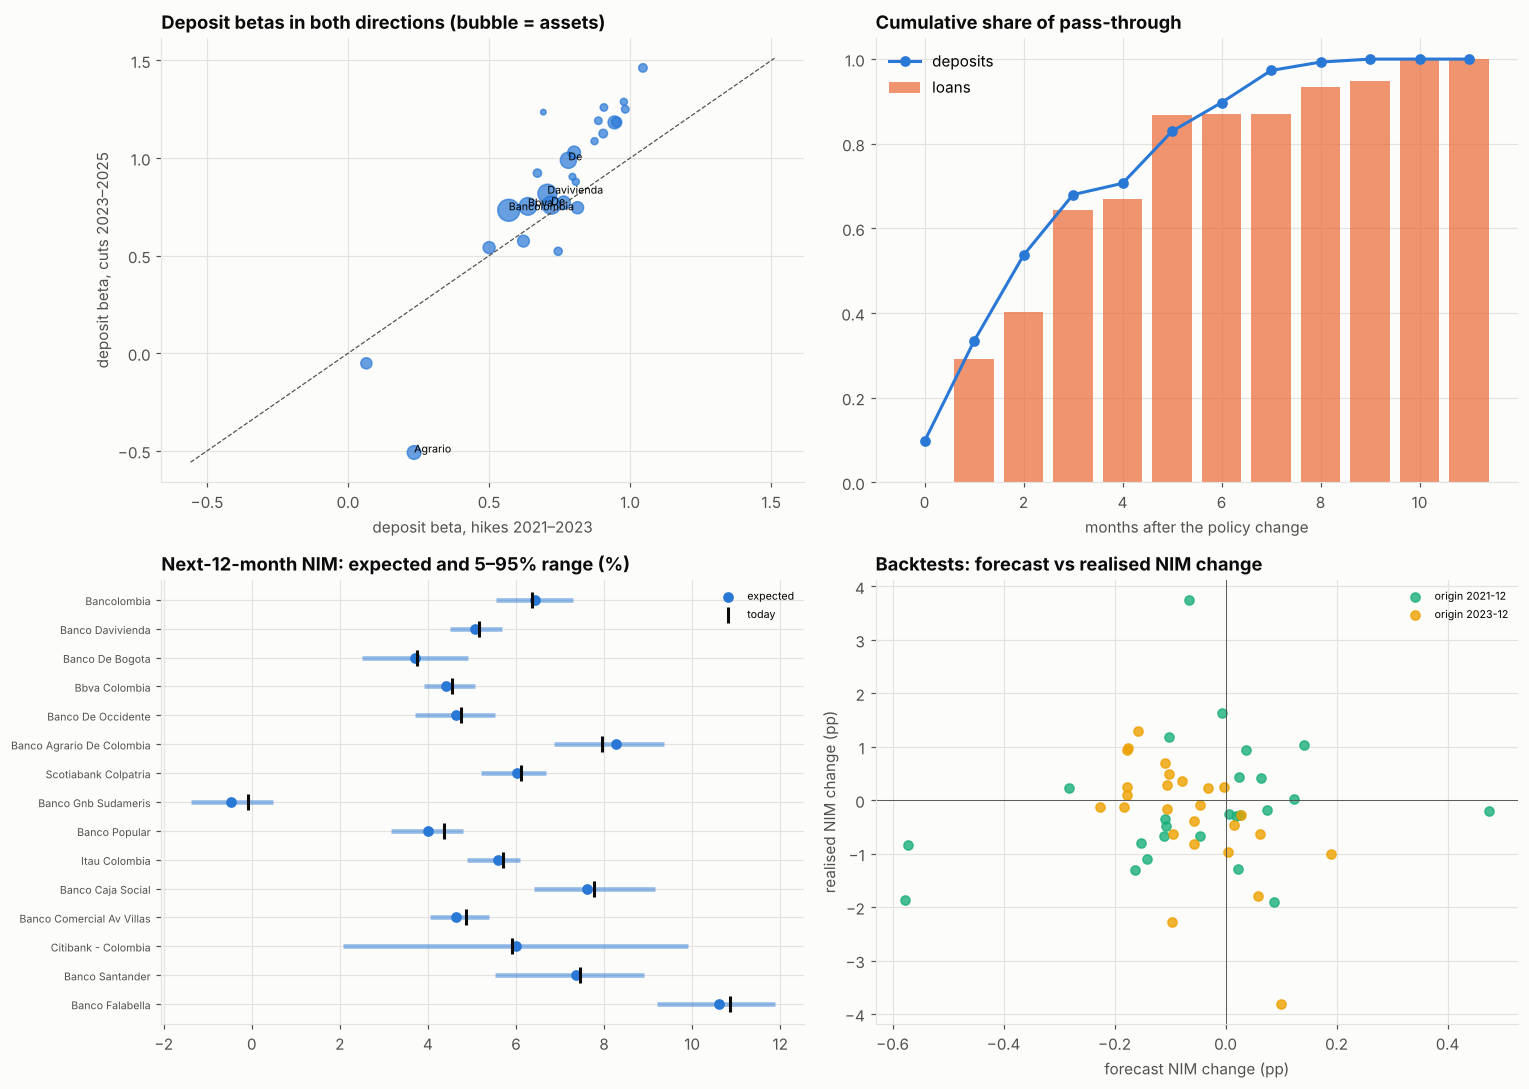

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
a = ax[0, 0]
h, c_ = CB["hikes 2021–2023"], CB["cuts 2023–2025"]
common_ = h.index.intersection(c_.index)
a.scatter(
    h.loc[common_, "deposit"],
    c_.loc[common_, "deposit"],
    s=np.sqrt(size.reindex(common_)) * 12,
    color=PALETTE[0],
    alpha=0.7,
)
lim = [
    min(h["deposit"].min(), c_["deposit"].min(), 0) - 0.05,
    max(h["deposit"].max(), c_["deposit"].max()) + 0.05,
]
a.plot(lim, lim, color=INK_2, lw=0.8, ls="--")
for b in size.reindex(common_).sort_values(ascending=False).index[:6]:
    a.annotate(
        NAMES[b].replace("Banco ", "").split()[0],
        (h.loc[b, "deposit"], c_.loc[b, "deposit"]),
        fontsize=7,
    )
a.set_xlabel("deposit beta, hikes 2021–2023")
a.set_ylabel("deposit beta, cuts 2023–2025")
a.set_title("Deposit betas in both directions (bubble = assets)")
a = ax[0, 1]
a.bar(range(LAGS), np.cumsum(WL), color=PALETTE[1], alpha=0.7, label="loans")
a.plot(
    range(LAGS), np.cumsum(WD), color=PALETTE[0], marker="o", label="deposits"
)
a.set_xlabel("months after the policy change")
a.set_title("Cumulative share of pass-through")
a.legend()
a = ax[1, 0]
top = EAR.head(15).iloc[::-1]
yy = np.arange(len(top))
a.hlines(
    yy,
    top["5th percentile"],
    top["95th percentile"],
    color=PALETTE[0],
    lw=3,
    alpha=0.5,
)
a.scatter(
    top["expected NIM, next 12m"],
    yy,
    color=PALETTE[0],
    zorder=3,
    label="expected",
)
a.scatter(
    top["base NIM"], yy, color=INK, marker="|", s=120, zorder=3, label="today"
)
a.set_yticks(yy, top["bank"], fontsize=7)
a.set_title("Next-12-month NIM: expected and 5–95% range (%)")
a.legend(fontsize=7)
a = ax[1, 1]
for i, (k, fc) in enumerate(BT.items()):
    a.scatter(
        fc["expected NIM, next 12m"] - fc["base NIM"],
        fc["realised NIM"] - fc["base NIM"],
        color=PALETTE[i + 2],
        label=f"origin {k}",
        alpha=0.8,
    )
a.axhline(0, color=INK_2, lw=0.6)
a.axvline(0, color=INK_2, lw=0.6)
a.set_xlabel("forecast NIM change (pp)")
a.set_ylabel("realised NIM change (pp)")
a.set_title("Backtests: forecast vs realised NIM change")
a.legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "01_ear_colombia")
plt.show()

In [9]:
dash = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Earnings-at-risk by bank (bp of assets)",
        "LightGBM: what drives deposit-cost changes (share of |SHAP|)",
    ),
)
e = EAR.sort_values("EaR (bp of assets)")
dash.add_trace(
    go.Bar(
        y=e["bank"],
        x=e["EaR (bp of assets)"],
        orientation="h",
        marker_color=PALETTE[0],
        name="EaR",
    ),
    1,
    1,
)
s = SHAP_G.iloc[::-1]
dash.add_trace(
    go.Bar(
        y=s.index,
        x=s.values,
        orientation="h",
        marker_color=PALETTE[2],
        name="SHAP",
    ),
    1,
    2,
)
dash.update_layout(
    height=750,
    width=1400,
    template="simple_white",
    showlegend=False,
    title="Earnings-at-risk for Colombian banks",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 9. Reading the results and limitations

*The data are the open supervisory reports as published when the notebook ran; recent months are revised, so figures shift slightly with each run. Simulations are seeded.*

**Two cycles, two answers.** The policy proxy rose 10.8 points between August 2021 and August 2023 and fell 3.6 points between November 2023 and September 2025.

| Median bank | Loan beta | Deposit beta | Savings-rate beta | New-CDT beta | NIM change |
|---|---|---|---|---|---|
| Hikes 2021–2023 | 0.53 | 0.79 | 0.55 | 0.99 | −1.44 pp |
| Cuts 2023–2025 | 0.72 | 0.88 | 0.51 | 1.16 | +0.84 pp |

- **Most Colombian banks are liability-sensitive.** Their funding costs moved more than their loan yields in both directions: the median bank's margin fell by 1.4 points in the hikes and recovered 0.8 in the cuts. Only 24% of banks gained margin while rates rose, among them Bancolombia (+0.6), Banco Agrario (+1.1) and Citibank (+3.8), which fund themselves with cheap savings and current accounts; Banco Popular lost 4.2 points.
- **New CDTs pass through one for one**, savings accounts about half. The difference between a bank's loan and deposit betas explains its margin change in the hikes almost entirely (correlation 0.90).
- **No downward stickiness.** The "rockets and feathers" pattern found in U.S. deposits does not appear: only 19% of the 26 banks with both cycles had a lower deposit beta in the cuts than in the hikes, and the two betas are highly correlated across banks (0.90). Pass-through is fast: 56% of a policy change reaches deposit costs within three months and 93% within six, with a 12-month pooled beta of 0.78.

**What drives deposit pass-through: mostly the rate itself.**

| Out of time, 950 bank-months since January 2024 | Monthly RMSE | Cumulative error since 2024 |
|---|---|---|
| No change | 22.8 bp | 232 bp |
| Pooled distributed lag | 17.9 bp | 88 bp |
| Distributed lag with bank characteristics | 17.9 bp | 85 bp |
| LightGBM | 19.0 bp | 128 bp |

- **A simple lag model is enough.** Adding balance-sheet characteristics improved the cumulative error only slightly, and LightGBM, trained on one cutting and one hiking cycle, was worse than the linear model.
- **SHAP:** 80% of LightGBM's attribution goes to past policy changes. Among bank characteristics the CDT and savings shares of deposits matter most (4% each), ahead of size (3%): banks funded with CDTs reprice faster.

**Earnings-at-risk today.**
- **Rate model:** fitted on 2018–2026, it has strong momentum (0.46) and almost no mean reversion. From 11.6% today, the 12-month 90% range of the policy proxy is 8.9–15.1%.
- **Rate risk alone is small.** Within a year the rate-only EaR is 4 bp of assets at Bancolombia, 12–26 bp at Banco de Bogotá, Davivienda and BBVA, and 57–75 bp at the microfinance banks and at Banco Popular and GNB Sudameris, whose deposit costs track rates much more closely than their loan yields. For 24 of 30 banks the margin falls when rates rise.
- **Everything else is larger.** Adding the bank's history of margin changes that rates do not explain raises EaR to 50–120 bp for the large banks and to several hundred for small and specialised ones (Citibank 392 bp, BTG Pactual 676, Banco Contactar 900).

**Backtests: the rate forecast is the weak link.**

| Origin | Policy proxy then → 12 months later | Forecast 90% rate range | Realised NIM inside 90% range | Direction right | MAE vs no change | MAE given realised rates |
|---|---|---|---|---|---|---|
| Dec 2021 | 2.6% → 10.8% | 1.5–4.4% | 52% (rate-only 4%) | 56% | 0.84 vs 0.88 pp | 0.83 pp |
| Dec 2023 | 12.5% → 9.3% | 11.2–18.2% | 77% (rate-only 19%) | 31% | 0.79 vs 0.75 pp | 0.71 pp |

- **The statistical rate model missed both turning points.** In December 2021 it gave no weight to a 10-point hike; in December 2023 momentum projected further hikes just before the cuts began.
- **Bank models were right more often given the actual rate path** (60% and 65% of directions right), but explained little of each bank's 12-month margin change: rate-only ranges contained the realised margin for only 4% and 19% of banks. Even with the non-rate residuals, coverage stayed below the nominal 90%.

**What this means for a Colombian bank's ALM.**
- **Measure betas in both directions and by product.** CDT funding reprices one for one within months; savings accounts are the franchise. Banks with low deposit betas gain when rates rise; most Colombian banks do not.
- **Do not rely on a statistical rate model for EaR.** It extrapolates the latest trend. Regulatory and management scenarios (parallel shocks, a full cycle in either direction) should set the rate paths, with betas and lags estimated as here.
- **Report EaR with and without non-rate risk.** Rate-driven EaR is typically a small fraction of how much a bank's margin moves in a year; mix, investment income and one-off items dominate.

**Limitations.**
- **Data:** monthly accounting yields are smoothed over three months but remain noisy; investments, money-market positions and borrowings are held at their current contribution, so treasury rate risk is not modelled.
- **Models:** two cycles give few independent observations of betas; balances are held constant; banks with short histories rely on shrinkage to the cross-bank average; the backtests cover only two origins.

In [10]:
SUMB.to_csv(OUT_DIR / "betas_by_cycle_summary.csv")
CBT.set_axis([" · ".join(c) for c in CBT.columns], axis=1).rename(
    index=NAMES
).to_csv(OUT_DIR / "betas_by_bank.csv")
EVAL.to_csv(OUT_DIR / "passthrough_models_out_of_time.csv")
LR_BETA.to_csv(OUT_DIR / "pooled_lag_model.csv")
SHAP_G.to_csv(OUT_DIR / "lightgbm_shap_shares.csv")
RATE_MODEL.to_csv(OUT_DIR / "rate_model.csv")
EAR.to_csv(OUT_DIR / "ear_by_bank.csv")
BTS.to_csv(OUT_DIR / "backtest_summary.csv")
pd.concat(BT).to_csv(OUT_DIR / "backtest_by_bank.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_ear_colombia.png, backtest_by_bank.csv, backtest_summary.csv, betas_by_bank.csv, betas_by_cycle_summary.csv, dashboard.html, dashboard.png, ear_by_bank.csv, lightgbm_shap_shares.csv, passthrough_models_out_of_time.csv, pooled_lag_model.csv, rate_model.csv


## References

- Basel Committee on Banking Supervision. (2016). *Standards: Interest rate risk in the banking book*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d368.htm
- Drechsler, I., Savov, A., & Schnabl, P. (2017). The deposits channel of monetary policy. *Quarterly Journal of Economics*, 132(4), 1819–1876. https://doi.org/10.1093/qje/qjx019
- Efron, B., & Morris, C. (1973). Stein's estimation rule and its competitors—An empirical Bayes approach. *Journal of the American Statistical Association*, 68(341), 117–130. https://doi.org/10.1080/01621459.1973.10481350
- Hutchison, D. E., & Pennacchi, G. G. (1996). Measuring rents and interest rate risk in imperfect financial markets: The case of retail bank deposits. *Journal of Financial and Quantitative Analysis*, 31(3), 399–417. https://doi.org/10.2307/2331398
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. In *Advances in Neural Information Processing Systems 30* (pp. 3146–3154).
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., Katz, R., Himmelfarb, J., Bansal, N., & Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Neumark, D., & Sharpe, S. A. (1992). Market structure and the nature of price rigidity: Evidence from the market for consumer deposits. *Quarterly Journal of Economics*, 107(2), 657–680. https://doi.org/10.2307/2118485
- Superintendencia Financiera de Colombia. (2026). *Información financiera con fines de supervisión – CUIF por moneda* and *Tasas de interés de captación y operaciones del mercado monetario* [Data sets]. datos.gov.co. https://www.datos.gov.co